# random_readings

**Question.** If faulty probes emit garbage N(0.5, 0.5) instead of dropping out, how do the models cope when the fault is flagged (oracle) and when it is undetected (silent)? And does training on silent garbage help?

**Setup.** `configs/experiment/random_readings.yaml`, Nektar u/v, N = 8 probes, seeds 0, 1, 2, 10 test draws per window. Part 1: the dropout_baseline run set. Part 2: SHRED, RobustSHREDv1 and v2 trained on silent garbage (p = 0.3, masked models get an all-zero mask). Missing and garbage use the same faulty-probe sets per severity. Models without a mask input (SHRED, SDN) behave the same under oracle and silent. Record: `experiments/random_readings/README.md`. Figures: `outputs/random_readings/nektar_uv/figures/`.

## How each model was trained

Run names are `<method>__<training corruption>`. Every trained run is trained separately per seed (0, 1, 2); the seed sets the split, the probe placement, the initialisation, and the noise and faults.

**Shared by every trained model**
- **Input:** 8 probes, each reading u and v, over a window of 10 time lags (SDN sees only the last lag). The probes are placed by block QR on the rank-16 POD basis of the training data, so placement depends on the seed. Readings are MinMax-scaled to [0, 1] per sensor on the training data.
- **Target:** the full u, v field at the last lag of the window (MSE in scaled units).
- **Data:** 80 / 10 / 10 % of lag windows for train / validation / test, interleaved.
- **Optimiser:** Adam, lr 1e-3, batch 64, up to 1000 epochs. Validation error is checked every 20 epochs; training stops after 5 checks without improvement and keeps the best weights.
- **Corruption during training:** applied fresh to every batch, so each epoch sees new noise and new fault patterns. It always includes measurement noise of σ = 5 % of the per-channel training std. Validation uses one fixed realisation of the run's own training corruption, so early stopping picks the model that is best under that corruption.
- **Size:** about 4.2 M parameters each, almost all in the shared decoder (hidden → 350 → 400 → full field).

**Architectures**
- **SHRED:** a 2-layer GRU (hidden 64) over the 10 lags, then the decoder. Faulty probes are just whatever values arrive (0 for missing, noise for garbage).
- **SHRED+mask (`shred_mask`):** SHRED with 8 extra inputs per lag, the 0/1 fault flags.
- **SDN:** the decoder alone on the last lag (no time history).
- **RobustSHREDv1:** at each lag, a GRU-state query attends over the 8 probes (each probe embedded from its u, v and a positional encoding of its coordinates, 4 heads, plus a learned null token). Probes flagged as faulty are excluded from attention. The attention output then feeds a GRU cell (64) and the decoder.
- **RobustSHREDv2:** at each lag, 8 learned latent tokens (dim 32) cross-attend to the probes (Senseiver-style encoder, flagged probes excluded). The latent sequence feeds a 2-layer GRU (64) and the decoder.
- **Gappy POD:** not trained. Least squares of the probe readings onto the leading 16 POD modes of the training data, clipped to the per-pixel training range. With oracle flags it drops the faulty probes; with silent faults it uses the garbage readings.

**Training corruptions**
- `noise`: measurement noise only; no faults.
- `missing`: noise, plus each probe fails with probability p = 0.3 per sample (never all 8). A failed probe reads 0 (the per-sensor training minimum) at every lag. Models with a mask input receive the true fault flags (oracle).
- `garbage`: noise, plus each probe fails with p = 0.3. A failed probe emits N(0.5, 0.5) at every lag and channel. The flags are always all zero (silent), so the model must notice the bad probes itself.
- `clean`: no corruption (only gappy POD, which ignores it).

**The runs**

| Run | Model | Trained on | Fault flags during training |
|---|---|---|---|
| `shred__noise` | SHRED | noise only | – (no mask input) |
| `shred__missing` | SHRED | missing probes (p = 0.3) | – (no mask input) |
| `shred_mask__missing` | SHRED + flags | missing probes (p = 0.3) | true flags |
| `sdn__noise` | SDN | noise only | – (no mask input) |
| `sdn__missing` | SDN | missing probes (p = 0.3) | – (no mask input) |
| `robust_shred_v1__missing` | RobustSHREDv1 | missing probes (p = 0.3) | true flags (failed probes excluded from attention) |
| `robust_shred_v2__missing` | RobustSHREDv2 | missing probes (p = 0.3) | true flags (failed probes excluded from attention) |
| `gappy_pod__clean` | Gappy POD | not trained (POD fit on training data) | – |
| `shred__garbage` | SHRED | garbage probes (p = 0.3) | – (no mask input) |
| `robust_shred_v1__garbage` | RobustSHREDv1 | garbage probes (p = 0.3) | always zero (silent) |
| `robust_shred_v2__garbage` | RobustSHREDv2 | garbage probes (p = 0.3) | always zero (silent) |

The first eight runs are the same as in `dropout_baseline`; with the same seeds they produce identical models. The three `__garbage` runs never saw a flag during training, so at test time with oracle flags their attention suddenly excludes probes, which they were never trained for.


In [1]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from get_shredded import plots as gp
from get_shredded.runner import load_config, load_results, load_seed_info, output_root, run_name

cfg = load_config(["+experiment=random_readings"])
ROOT = output_root(cfg)
RUNS = [run_name(r) for r in cfg.runs]
results = load_results(ROOT)
print(ROOT, f"{len(results)} run x seed results")

/Users/kaspervanderhorst/projects/shred/get-shredded/outputs/random_readings/nektar_uv 33 run x seed results


In [2]:
def table(runs, conds):
    """Markdown table of mean ± std over seeds (relative L2 error) per run and condition."""
    rows = ["| Run | " + " | ".join(conds) + " |", "|---" + "|---:" * len(conds) + "|"]
    for m in gp.available_methods(results, runs):
        cells = [f"{mu:.4f} ± {sd:.4f}" for mu, sd, _ in (gp.metric_over_seeds(results, m, c) for c in conds)]
        rows.append(f"| {m} | " + " | ".join(cells) + " |")
    return Markdown("\n".join(rows))

In [3]:
GARBAGE = [r for r in RUNS if r.endswith("__garbage")]
BASE = [r for r in RUNS if r not in GARBAGE]
P03 = ["missing_oracle_p0.3", "garbage_oracle_p0.3", "garbage_silent_p0.3"]

## Part 1: dropout-trained models under garbage (p = 0.3, mean ± std over seeds)

In [4]:
display(table(BASE, ["clean"] + P03))

| Run | clean | missing_oracle_p0.3 | garbage_oracle_p0.3 | garbage_silent_p0.3 |
|---|---:|---:|---:|---:|
| shred__noise | 0.0040 ± 0.0006 | 0.1589 ± 0.0062 | 0.1188 ± 0.0075 | 0.1188 ± 0.0075 |
| shred__missing | 0.0102 ± 0.0027 | 0.0145 ± 0.0035 | 0.1505 ± 0.0115 | 0.1505 ± 0.0115 |
| shred_mask__missing | 0.0099 ± 0.0013 | 0.0113 ± 0.0018 | 0.1281 ± 0.0095 | 0.1084 ± 0.0059 |
| sdn__noise | 0.0040 ± 0.0004 | 0.1803 ± 0.0061 | 0.1679 ± 0.0102 | 0.1679 ± 0.0102 |
| sdn__missing | 0.0101 ± 0.0012 | 0.0243 ± 0.0017 | 0.1900 ± 0.0206 | 0.1900 ± 0.0206 |
| robust_shred_v1__missing | 0.0101 ± 0.0008 | 0.0146 ± 0.0012 | 0.0146 ± 0.0012 | 0.1489 ± 0.0131 |
| robust_shred_v2__missing | 0.0098 ± 0.0007 | 0.0143 ± 0.0016 | 0.0143 ± 0.0016 | 0.1381 ± 0.0180 |
| gappy_pod__clean | 0.0007 ± 0.0000 | 0.0916 ± 0.0089 | 0.0916 ± 0.0089 | 0.2349 ± 0.0085 |

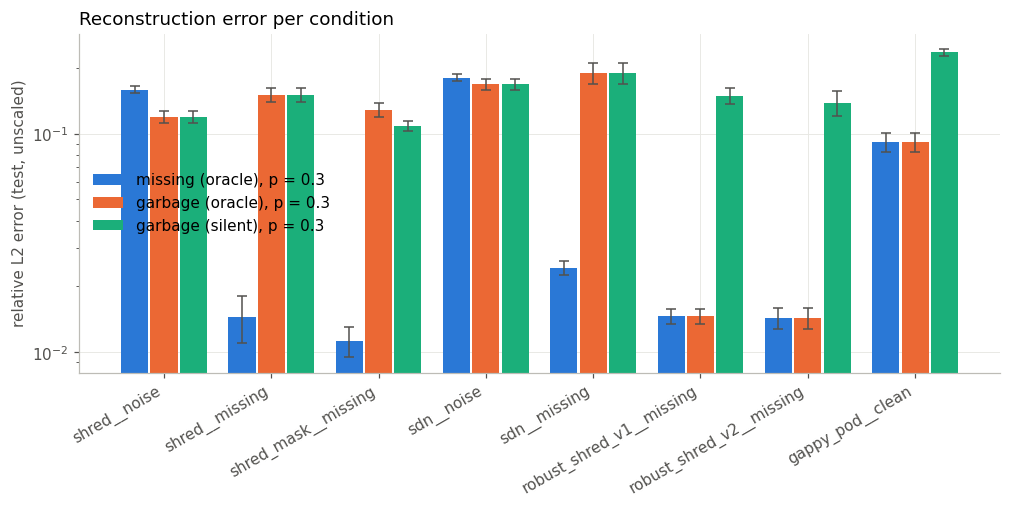

In [5]:
ax = gp.plot_error_bars(results, BASE, tuple(P03))
ax.set_yscale("log"); gp.save(ax.figure, ROOT, "error_bars_p0.3"); plt.show()

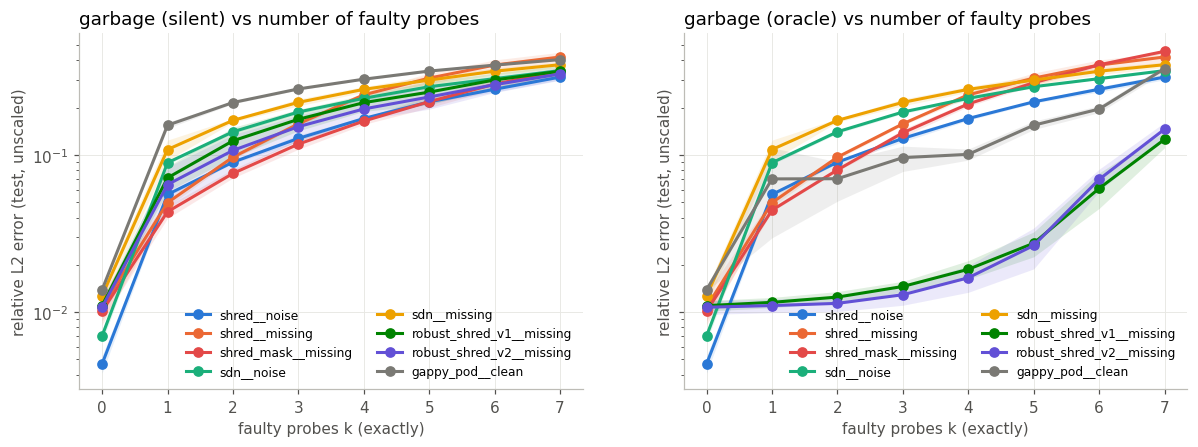

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, prefix in zip(axes, ("garbage_silent", "garbage_oracle")):
    gp.plot_exact_k(results, BASE, prefix, ax=ax, logy=True)
gp.save(fig, ROOT, "garbage_exact_k"); plt.show()

## Part 2: trained on silent garbage vs trained on dropout

In [7]:
PAIRS = [r for g in GARBAGE for r in (g.replace("__garbage", "__missing"), g)]
display(table(PAIRS, ["clean"] + P03))

| Run | clean | missing_oracle_p0.3 | garbage_oracle_p0.3 | garbage_silent_p0.3 |
|---|---:|---:|---:|---:|
| shred__missing | 0.0102 ± 0.0027 | 0.0145 ± 0.0035 | 0.1505 ± 0.0115 | 0.1505 ± 0.0115 |
| shred__garbage | 0.0197 ± 0.0025 | 0.0881 ± 0.0157 | 0.0490 ± 0.0072 | 0.0490 ± 0.0072 |
| robust_shred_v1__missing | 0.0101 ± 0.0008 | 0.0146 ± 0.0012 | 0.0146 ± 0.0012 | 0.1489 ± 0.0131 |
| robust_shred_v1__garbage | 0.0318 ± 0.0026 | 0.0878 ± 0.0101 | 0.0878 ± 0.0101 | 0.0736 ± 0.0055 |
| robust_shred_v2__missing | 0.0098 ± 0.0007 | 0.0143 ± 0.0016 | 0.0143 ± 0.0016 | 0.1381 ± 0.0180 |
| robust_shred_v2__garbage | 0.0162 ± 0.0001 | 0.0423 ± 0.0022 | 0.0423 ± 0.0022 | 0.0329 ± 0.0031 |

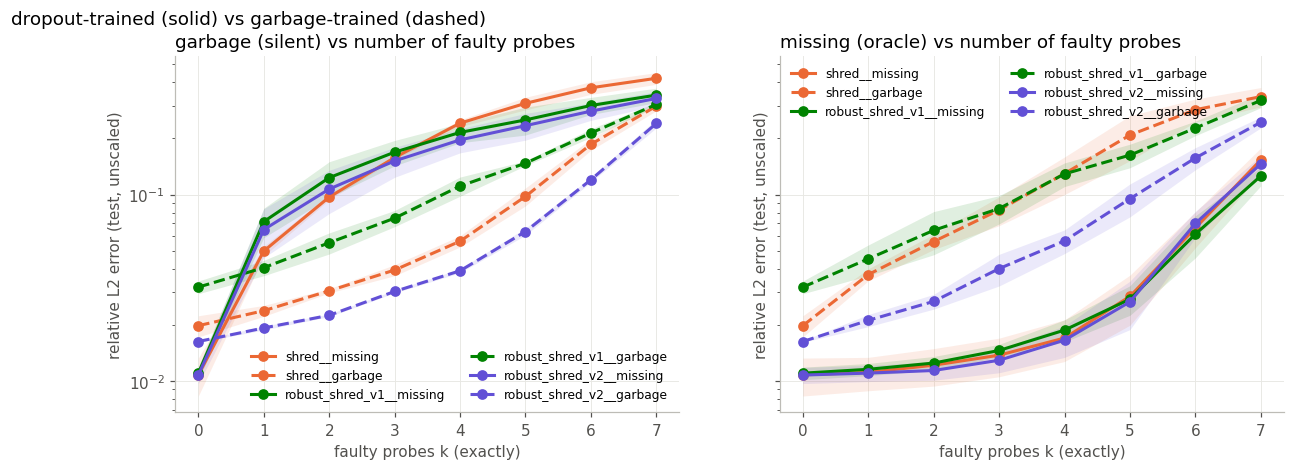

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, prefix in zip(axes, ("garbage_silent", "missing_oracle")):
    gp.plot_exact_k(results, PAIRS, prefix, ax=ax, logy=True)
fig.suptitle("dropout-trained (solid) vs garbage-trained (dashed)", x=0.01, ha="left")
gp.save(fig, ROOT, "garbage_trained_exact_k"); plt.show()

## Reconstructions under silent garbage, p = 0.3 (seed 0, test window 0)

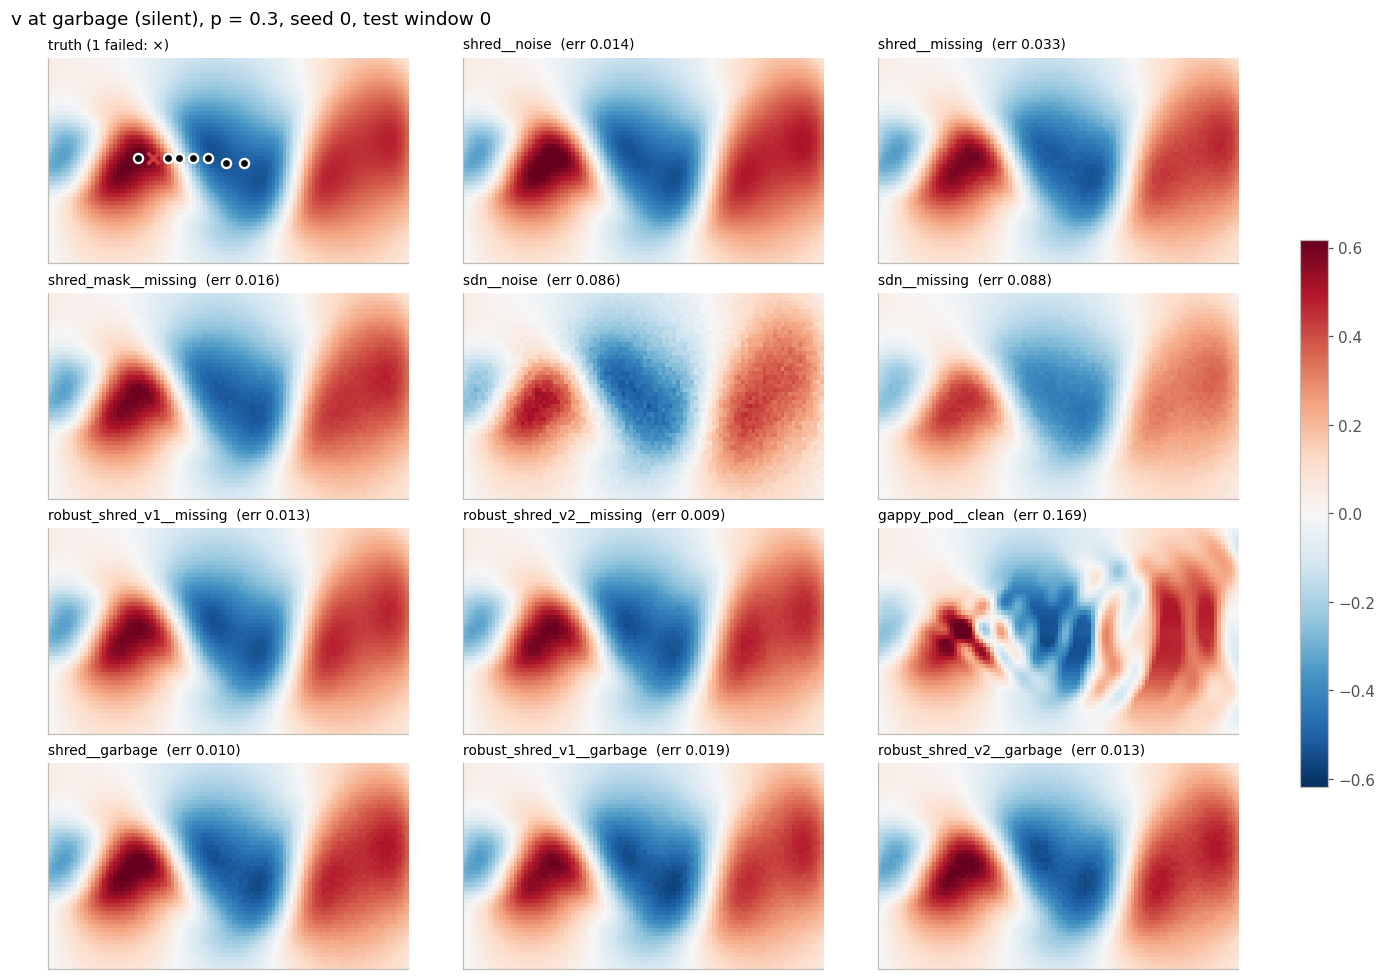

In [9]:
fig = gp.plot_reconstruction_panel(ROOT, results, RUNS, seed=0, cond="garbage_silent_p0.3", channel=1)
gp.save(fig, ROOT, "panel_v_garbage_silent"); plt.show()